# Previsão de NO₂ com redes recorrentes: RNN, LSTM e GRU

Comparação de três redes recorrentes (RNN simples, LSTM e GRU) e de um baseline de persistência na previsão da concentração média diária de dióxido de nitrogênio (NO₂) do dia seguinte, usando apenas os 14 dias anteriores de quatro poluentes.

**Autores:** Elton Vinicios Almeida de Oliveira, Emerson dos Santos Silva e Kelvin Douglas Ribeiro Rabelo.

**Contexto.** Trabalho desenvolvido como avaliação (Global Solution 02/2026, tema CitizenTech) da disciplina *Artificial Intelligence & Deep Learning Applications*, da FIAP. O enunciado original não está reproduzido aqui; cada seção descreve, com as nossas palavras, o que a etapa resolve. As respostas mantêm as letras (a), (b), (c) e (d) das etapas da avaliação.

**Problema.** A entrada é uma janela com 14 dias de NO₂, NOx, CO e benzeno; a saída é o NO₂ médio do dia seguinte, em µg/m³. Nenhuma medição do próprio dia previsto entra na janela.

**Protocolo.** Divisão cronológica em treino, validação e teste (70% / 15% / 15%); normalização ajustada só com o treino; uma configuração por família de rede, com no máximo 30 épocas; escolha do candidato pelo MAE de validação, registrada antes de consultar o teste; MAE e RMSE sempre na unidade original.

**Dados.** *Air Quality* (UCI Machine Learning Repository), médias diárias de 391 dias consecutivos (10/03/2004 a 04/04/2005) de uma cidade italiana, no arquivo `qualidade_do_ar_diario.csv`.

In [1]:
import os
import random
import time

os.environ.setdefault('KERAS_BACKEND', 'tensorflow')   # precisa vir antes de importar o Keras

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import keras
from keras import layers

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
keras.utils.set_random_seed(SEMENTE)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Keras:', keras.__version__, '| backend:', keras.backend.backend())


Keras: 3.15.1 | backend: tensorflow


In [2]:
# Médias diárias dos quatro poluentes. COLUNAS define a ordem das variáveis nas janelas (NO2 primeiro).
COLUNAS = ['NO2(GT)', 'NOx(GT)', 'CO(GT)', 'C6H6(GT)']
df = (pd.read_csv('qualidade_do_ar_diario.csv', parse_dates=['data'])
        .sort_values('data').reset_index(drop=True))
print(f'Base carregada: {len(df)} dias | {df.data.min():%d/%m/%Y} a {df.data.max():%d/%m/%Y}')


Base carregada: 391 dias | 10/03/2004 a 04/04/2005


## 1. Diagnóstico e exploração dos dados

(a) Integridade da base: dimensões, período, estatísticas do NO₂, valores ausentes, datas repetidas e lacunas no calendário. (b) Série diária de NO₂ com média móvel de 7 dias e correlação com o NOx.

Primeiras observações:


,data,CO(GT),C6H6(GT),NOx(GT),NO2(GT)
0,2004-03-10,1.967,8.45,132.0,108.8
1,2004-03-11,2.173,7.98,139.8,97.7
2,2004-03-12,2.756,12.13,171.7,114.6
3,2004-03-13,2.640,10.92,180.8,117.4
4,2004-03-14,2.442,9.64,144.6,109.7
5,2004-03-15,3.402,16.09,209.8,117.1
6,2004-03-16,2.681,13.50,176.2,115.8
7,2004-03-17,2.971,15.24,194.2,117.9
8,2004-03-18,2.615,13.80,171.7,123.4
9,2004-03-19,2.867,13.52,174.0,115.1


Dimensões: 391 linhas x 5 colunas
Período: 10/03/2004 a 04/04/2005

Estatísticas descritivas de NO2(GT) [µg/m³]:


,count,mean,std,min,25%,50%,75%,max
NO2(GT),391.0,109.64,31.39,37.2,87.5,106.9,127.7,218.4


Valores ausentes por coluna:
data        0
NO2(GT)     0
NOx(GT)     0
CO(GT)      0
C6H6(GT)    0

Datas repetidas: 0
Dias ausentes na sequência cronológica: 0
Todos os intervalos entre linhas são de 1 dia: True
Valores negativos (ex.: marcador -200 da base horária): 0

Necessidade de imputação: NÃO


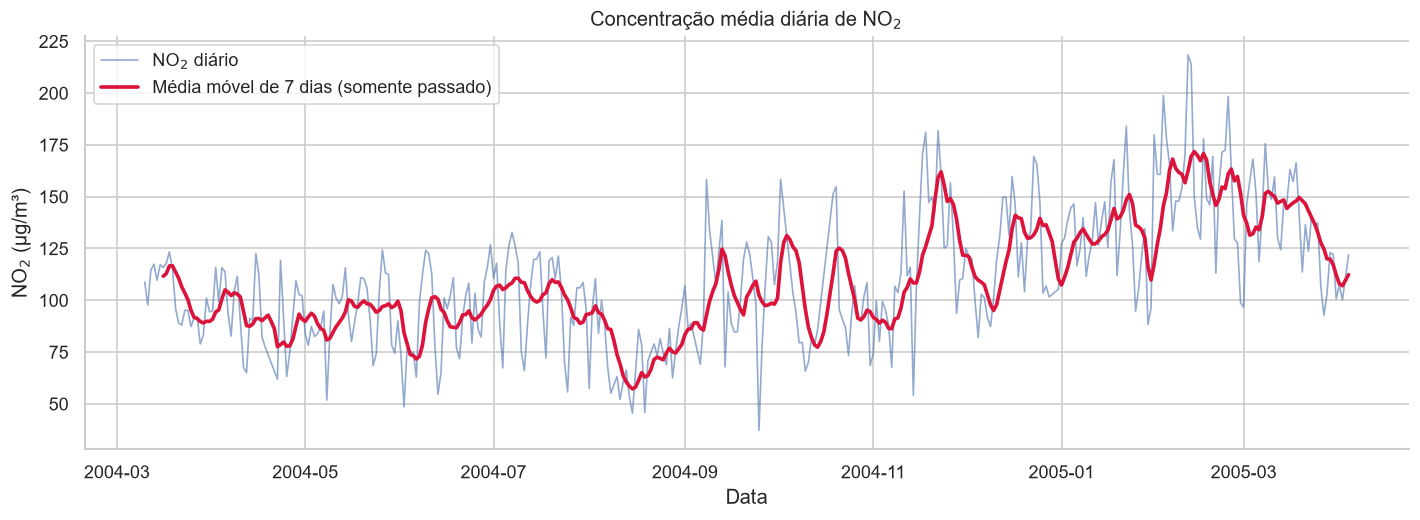

Correlação de Pearson entre NO2(GT) e NOx(GT): r = 0.719 (n = 391)


In [3]:
# ---------------------------------------------------------------
# (a) Diagnóstico de qualidade
# ---------------------------------------------------------------
print('Primeiras observações:')
display(df.head(10))

print(f'Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas')
print(f'Período: {df["data"].min():%d/%m/%Y} a {df["data"].max():%d/%m/%Y}')

print('\nEstatísticas descritivas de NO2(GT) [µg/m³]:')
display(df['NO2(GT)'].describe().to_frame().T.round(2))

# Valores ausentes, datas repetidas e lacunas na sequência diária.
ausentes = df[['data'] + COLUNAS].isna().sum()
n_datas_duplicadas = int(df['data'].duplicated().sum())
calendario = pd.date_range(df['data'].min(), df['data'].max(), freq='D')
lacunas_calendario = calendario.difference(df['data'])
passo_unico = np.all(np.diff(df['data'].to_numpy()) == np.timedelta64(1, 'D'))

print('Valores ausentes por coluna:')
print(ausentes.to_string())
print(f'\nDatas repetidas: {n_datas_duplicadas}')
print(f'Dias ausentes na sequência cronológica: {len(lacunas_calendario)}')
print(f'Todos os intervalos entre linhas são de 1 dia: {bool(passo_unico)}')
print(f'Valores negativos (ex.: marcador -200 da base horária): {int((df[COLUNAS] < 0).sum().sum())}')

precisa_imputar = bool(ausentes.sum() > 0 or len(lacunas_calendario) > 0 or n_datas_duplicadas > 0)
print(f'\nNecessidade de imputação: {"SIM" if precisa_imputar else "NÃO"}')

# ---------------------------------------------------------------
# (b) Série de NO2, média móvel causal de 7 dias e correlação com NOx
# ---------------------------------------------------------------
# rolling(7) usa o dia corrente e os 6 anteriores (janela alinhada à direita, sem center=True),
# portanto não incorpora nenhuma informação futura.
media_7d = df['NO2(GT)'].rolling(window=7, min_periods=7).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df['data'], df['NO2(GT)'], lw=1.0, alpha=0.6, label='NO$_2$ diário')
ax.plot(df['data'], media_7d, lw=2.2, color='crimson', label='Média móvel de 7 dias (somente passado)')
ax.set_title('Concentração média diária de NO$_2$')
ax.set_xlabel('Data')
ax.set_ylabel('NO$_2$ (µg/m³)')
ax.legend()
fig.tight_layout()
plt.show()

r_no2_nox = df['NO2(GT)'].corr(df['NOx(GT)'])
print(f'Correlação de Pearson entre NO2(GT) e NOx(GT): r = {r_no2_nox:.3f} (n = {len(df)})')


**(a)** O que as verificações acima mostraram: 391 dias e 5 colunas, de 10/03/2004 a 04/04/2005; nenhuma célula vazia; nenhuma data duplicada; nenhum buraco no calendário (cada linha está exatamente um dia depois da anterior). Também não há valores negativos, que na base horária da UCI sinalizam falha de sensor. Os dados diários podem ser usados como estão, **sem imputação**. Fica registrado que não temos como saber quantas horas válidas entraram em cada média diária.

**(b)** O coeficiente entre NO₂ e NOx foi **r = 0,72**: as duas séries sobem e descem juntas na maior parte dos dias, o que combina com o fato de o NO₂ ser um dos componentes do NOx. Esse número descreve apenas o quanto elas variam juntas de forma linear. Tráfego, clima e época do ano afetam as duas ao mesmo tempo, então ele não permite dizer que uma provoca a outra.

## 2. Janelas, divisão temporal e normalização

(a) Montagem das janelas de 14 dias e divisão cronológica das amostras. (b) Normalização ajustada apenas com o treino. (c) Gráfico da divisão pela data do alvo. (d) Por que as duas práticas evitadas seriam vazamento de dados.

Amostras supervisionadas: n = 377 (= 391 dias - 14 de contexto inicial)
Cortes: int(0.70*n) = 263 | int(0.85*n) = 320



,conjunto,amostras,proporção (%),formato X,formato y,primeiro alvo,último alvo
0,Treino,263,69.8,"(263, 14, 4)","(263,)",24/03/2004,11/12/2004
1,Validação,57,15.1,"(57, 14, 4)","(57,)",12/12/2004,06/02/2005
2,Teste,57,15.1,"(57, 14, 4)","(57,)",07/02/2005,04/04/2005


Parâmetros dos scalers (estimados apenas com o treino):


,média,desvio-padrão
NO2(GT),97.612,24.709
NOx(GT),206.083,143.471
CO(GT),2.140,0.871
C6H6(GT),10.716,4.175


Alvo NO2: média = 97.17 | desvio-padrão = 25.10 µg/m³

Formatos normalizados -> X_treino (263, 14, 4) | X_val (57, 14, 4) | X_teste (57, 14, 4)
Alvos normalizados   -> y_treino_pad (263,) | y_val_pad (57,)
Média/desvio de X_treino por variável: [-0.02 -0.01 -0.01  0.01] / [1.02 1.01 1.01 1.01]


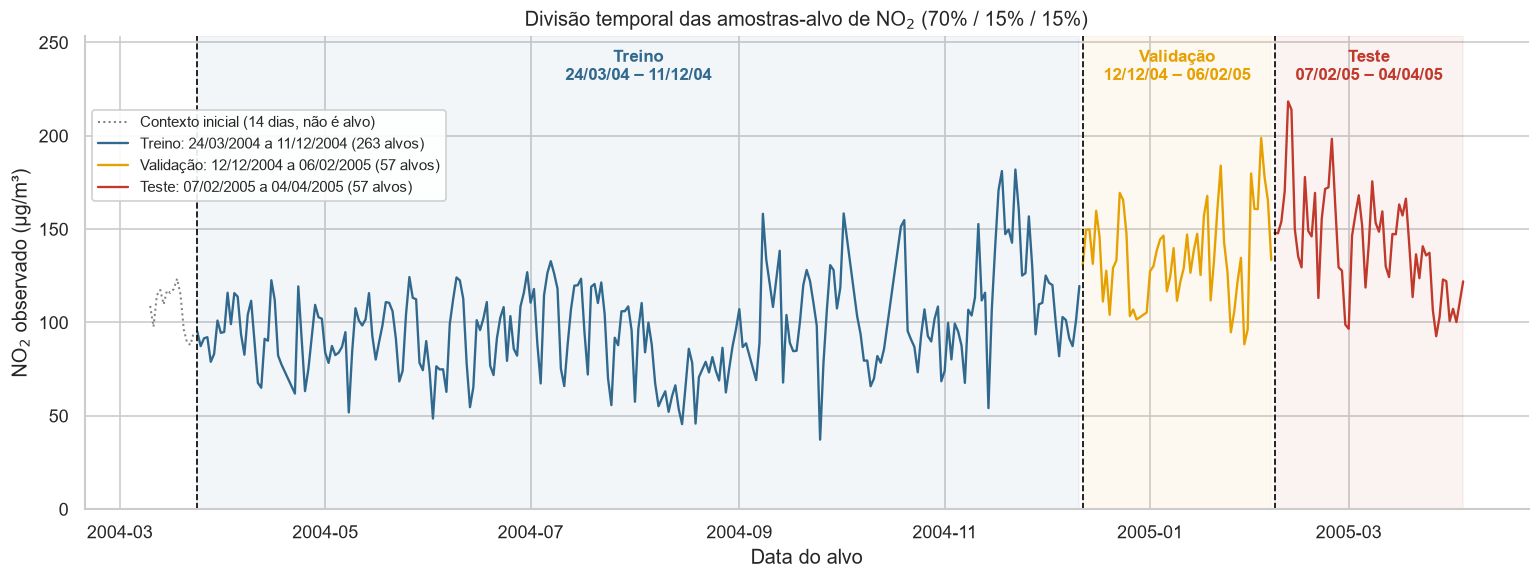

In [4]:
# ---------------------------------------------------------------
# (a) Janelas supervisionadas e divisão cronológica
# ---------------------------------------------------------------
TAM_JANELA = 14
N_POLUENTES = len(COLUNAS)
COL_NO2 = COLUNAS.index('NO2(GT)')          # NO2 é a coluna 0 em COLUNAS

valores = df[COLUNAS].to_numpy(dtype='float32')   # ordem: NO2, NOx, CO, C6H6
datas = df['data'].to_numpy()

# Amostra com alvo no dia t (linha t): entradas = linhas t-14 ... t-1; alvo = NO2 da linha t.
janelas_brutas, alvos_brutos, dias_alvo = [], [], []
for t in range(TAM_JANELA, len(df)):
    janelas_brutas.append(valores[t - TAM_JANELA:t])     # o fatiamento exclui a linha t (dia previsto)
    alvos_brutos.append(valores[t, COL_NO2])
    dias_alvo.append(datas[t])
janelas_brutas = np.asarray(janelas_brutas, dtype='float32')
alvos_brutos = np.asarray(alvos_brutos, dtype='float32')
dias_alvo = pd.DatetimeIndex(dias_alvo)

n = len(janelas_brutas)
fim_treino = int(0.70 * n)
fim_val = int(0.85 * n)

X_treino_bruto, y_treino = janelas_brutas[:fim_treino], alvos_brutos[:fim_treino]
X_val_bruto, y_val = janelas_brutas[fim_treino:fim_val], alvos_brutos[fim_treino:fim_val]
X_teste_bruto, y_teste = janelas_brutas[fim_val:], alvos_brutos[fim_val:]
dias_treino = dias_alvo[:fim_treino]
dias_val = dias_alvo[fim_treino:fim_val]
dias_teste = dias_alvo[fim_val:]

# Verificações da convenção temporal.
assert dias_alvo[0] == df['data'].iloc[TAM_JANELA]                    # 1º alvo = 15º dia da base
assert np.allclose(janelas_brutas[0], valores[:TAM_JANELA])                   # 1ª janela = 14 primeiros dias
assert np.allclose(janelas_brutas[:, -1, COL_NO2], df['NO2(GT)'].to_numpy()[TAM_JANELA - 1:-1])  # último dia da janela = t-1
assert dias_treino.max() < dias_val.min() < dias_val.max() < dias_teste.min()      # sem sobreposição de alvos

print(f'Amostras supervisionadas: n = {n} (= {len(df)} dias - {TAM_JANELA} de contexto inicial)')
print(f'Cortes: int(0.70*n) = {fim_treino} | int(0.85*n) = {fim_val}\n')
quadro_divisao = pd.DataFrame({
    'conjunto': ['Treino', 'Validação', 'Teste'],
    'amostras': [len(y_treino), len(y_val), len(y_teste)],
    'proporção (%)': np.round(100 * np.array([len(y_treino), len(y_val), len(y_teste)]) / n, 1),
    'formato X': [X_treino_bruto.shape, X_val_bruto.shape, X_teste_bruto.shape],
    'formato y': [y_treino.shape, y_val.shape, y_teste.shape],
    'primeiro alvo': [d.min().strftime('%d/%m/%Y') for d in (dias_treino, dias_val, dias_teste)],
    'último alvo': [d.max().strftime('%d/%m/%Y') for d in (dias_treino, dias_val, dias_teste)],
})
display(quadro_divisao)

# ---------------------------------------------------------------
# (b) Normalização ajustada SOMENTE no treinamento
# ---------------------------------------------------------------
# As linhas da base que servem de entrada ao treino são 0 ... fim_treino + TAM_JANELA - 2
# (a janela da última amostra de treino termina no dia anterior ao seu alvo).
dias_de_entrada_treino = valores[:fim_treino + TAM_JANELA - 1]
padronizador_x = StandardScaler().fit(dias_de_entrada_treino)             # 4 entradas, só treino
padronizador_y = StandardScaler().fit(y_treino.reshape(-1, 1))           # alvo, só treino

def padronizar_entradas(X):
    """Aplica padronizador_x a cada dia de cada janela e devolve (exemplos, 14, 4)."""
    return padronizador_x.transform(X.reshape(-1, N_POLUENTES)).reshape(-1, TAM_JANELA, N_POLUENTES).astype('float32')

X_treino = padronizar_entradas(X_treino_bruto)
X_val = padronizar_entradas(X_val_bruto)
X_teste = padronizar_entradas(X_teste_bruto)       # apenas transformado; só será usado na seção 4
y_treino_pad = padronizador_y.transform(y_treino.reshape(-1, 1)).ravel().astype('float32')
y_val_pad = padronizador_y.transform(y_val.reshape(-1, 1)).ravel().astype('float32')
# X_val_bruto, X_teste_bruto, y_val e y_teste permanecem na escala original (µg/m³).

print('Parâmetros dos scalers (estimados apenas com o treino):')
display(pd.DataFrame({'média': padronizador_x.mean_, 'desvio-padrão': padronizador_x.scale_}, index=COLUNAS).round(3))
print(f'Alvo NO2: média = {padronizador_y.mean_[0]:.2f} | desvio-padrão = {padronizador_y.scale_[0]:.2f} µg/m³')
print(f'\nFormatos normalizados -> X_treino {X_treino.shape} | X_val {X_val.shape} | X_teste {X_teste.shape}')
print(f'Alvos normalizados   -> y_treino_pad {y_treino_pad.shape} | y_val_pad {y_val_pad.shape}')
print(f'Média/desvio de X_treino por variável: {X_treino.mean(axis=(0, 1)).round(2)} / {X_treino.std(axis=(0, 1)).round(2)}')

# ---------------------------------------------------------------
# (c) Gráfico único da divisão temporal (pertencimento pela DATA DO ALVO)
# ---------------------------------------------------------------
PALETA_PARTICOES = {'Treino': '#31688e', 'Validação': '#e6a100', 'Teste': '#c0392b'}
particoes = [('Treino', dias_treino, y_treino), ('Validação', dias_val, y_val), ('Teste', dias_teste, y_teste)]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['data'].iloc[:TAM_JANELA], df['NO2(GT)'].iloc[:TAM_JANELA], color='gray', lw=1.2, ls=':',
        label=f'Contexto inicial ({TAM_JANELA} dias, não é alvo)')
topo = float(df['NO2(GT)'].max())
for nome, d, y in particoes:
    ax.plot(d, y, color=PALETA_PARTICOES[nome], lw=1.4,
            label=f'{nome}: {d.min():%d/%m/%Y} a {d.max():%d/%m/%Y} ({len(y)} alvos)')
    ax.axvspan(d.min(), d.max(), color=PALETA_PARTICOES[nome], alpha=0.06)
    meio = d.min() + (d.max() - d.min()) / 2
    ax.text(meio, topo * 1.13, f'{nome}\n{d.min():%d/%m/%y} – {d.max():%d/%m/%y}',
            ha='center', va='top', fontsize=10, color=PALETA_PARTICOES[nome], fontweight='bold')
for fronteira in (dias_treino.min(), dias_val.min(), dias_teste.min()):
    ax.axvline(fronteira, color='black', ls='--', lw=1.0)
ax.set_ylim(0, topo * 1.16)
ax.set_title('Divisão temporal das amostras-alvo de NO$_2$ (70% / 15% / 15%)')
ax.set_xlabel('Data do alvo')
ax.set_ylabel('NO$_2$ observado (µg/m³)')
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 0.86), fontsize=9, framealpha=0.9)
fig.tight_layout()
plt.show()


**(d)** Vazamento de dados é qualquer situação em que o modelo é treinado ou avaliado com algo que não teria em mãos na hora de prever de verdade. Os dois casos a seguir se encaixam nessa definição.

1. *Scaler ajustado com validação ou teste.* Média e desvio-padrão são calculados a partir dos dados, portanto também são "aprendidos". Se incluírem dias de validação ou teste, o treino passa a depender de valores futuros. Nesta base o futuro é diferente do passado: os meses de inverno têm NO₂ mais alto que o período de treino (média de treino ≈ 97 µg/m³). O erro medido ficaria menor que o erro real de operação. Por isso os dois scalers foram ajustados só com o treino e apenas aplicados aos outros conjuntos.
2. *Poluentes do próprio dia previsto.* A previsão para o dia $t$ precisa sair antes de o dia $t$ terminar, quando as médias desse dia ainda não existem. Além disso, NOx, CO e benzeno do mesmo dia acompanham o NO₂ (r ≈ 0,72 no caso do NOx); usá-los seria quase entregar a resposta ao modelo. Nossas janelas terminam em $t-1$.

## 3. RNN, LSTM e GRU: treinamento e comparação

(a) Construção e treino das três redes. (b) Justificativa da arquitetura. (c) Curvas de perda e leitura do treinamento. (d) Tabela comparativa e rede escolhida pela validação.

In [5]:
# ---------------------------------------------------------------
# Hiperparâmetros COMUNS às três redes (protocolo comparável)
# ---------------------------------------------------------------
HIPERPARAMS = {
    'unidades_recorrentes': 16,      # largura da única camada recorrente
    'otimizador': 'Adam',
    'taxa_aprendizado': 1e-3,
    'perda': 'mse',                  # calculada sobre o alvo normalizado
    'batch_size': 16,
    'epocas_max': 30,                # limite adotado, igual para as três
    'paciencia': 6,                  # EarlyStopping em val_loss
    'semente': SEMENTE,
}
CELULAS_RECORRENTES = {'RNN': layers.SimpleRNN, 'LSTM': layers.LSTM, 'GRU': layers.GRU}

# Reprodutibilidade: operações determinísticas quando o backend é TensorFlow.
if keras.backend.backend() == 'tensorflow':
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')             # oculta avisos informativos do TensorFlow
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception as erro:
        print('Determinismo não habilitado:', erro)

def criar_rede(nome):
    """Entrada (14, 4) -> camada recorrente (16 unidades) -> Dense(1) linear."""
    modelo = keras.Sequential(name=f'modelo_{nome}', layers=[
        keras.Input(shape=(TAM_JANELA, N_POLUENTES), name='janela_14_dias'),
        CELULAS_RECORRENTES[nome](HIPERPARAMS['unidades_recorrentes'], name=f'camada_{nome.lower()}'),
        layers.Dense(1, name='no2_dia_seguinte'),
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=HIPERPARAMS['taxa_aprendizado']),
                   loss=HIPERPARAMS['perda'], metrics=['mae'])
    return modelo

def para_ug_m3(pred_norm):
    """Converte a saída normalizada da rede para µg/m³."""
    return padronizador_y.inverse_transform(np.asarray(pred_norm).reshape(-1, 1)).ravel()

redes, curvas_treino, duracoes, estimativas_val = {}, {}, {}, {}
for nome in CELULAS_RECORRENTES:
    keras.utils.set_random_seed(HIPERPARAMS['semente'])        # mesma semente antes de cada rede
    modelo = criar_rede(nome)
    modelo.summary()
    parada = keras.callbacks.EarlyStopping(monitor='val_loss', patience=HIPERPARAMS['paciencia'],
                                           restore_best_weights=True)
    inicio = time.perf_counter()
    hist = modelo.fit(X_treino, y_treino_pad,
                      validation_data=(X_val, y_val_pad),   # o teste NÃO é usado aqui
                      epochs=HIPERPARAMS['epocas_max'], batch_size=HIPERPARAMS['batch_size'],
                      shuffle=True, callbacks=[parada], verbose=0)
    duracoes[nome] = time.perf_counter() - inicio
    redes[nome], curvas_treino[nome] = modelo, hist.history
    estimativas_val[nome] = para_ug_m3(modelo.predict(X_val, verbose=0))
    melhor = int(np.argmin(hist.history['val_loss'])) + 1
    print(f'>> {nome}: {len(hist.history["loss"])} épocas executadas | melhor época = {melhor} '
          f'(val_loss = {min(hist.history["val_loss"]):.4f}) | tempo = {duracoes[nome]:.1f} s\n')

print('Hiperparâmetros e protocolo registrados:')
display(pd.Series(HIPERPARAMS, name='valor').to_frame())
print('Critério de parada: EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True), '
      'com teto de 30 épocas; os pesos finais são os da melhor época de validação.')


Model: "modelo_RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ camada_rnn (SimpleRNN)          │ (None, 16)             │           336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ no2_dia_seguinte (Dense)        │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

>> RNN: 30 épocas executadas | melhor época = 30 (val_loss = 0.7621) | tempo = 6.4 s



... (10 outputs left out)

 Non-trainable params: 0 (0.00 B)

>> GRU: 22 épocas executadas | melhor época = 16 (val_loss = 0.7406) | tempo = 7.3 s

Hiperparâmetros e protocolo registrados:


,valor
unidades_recorrentes,16
otimizador,Adam
taxa_aprendizado,0.001
perda,mse
batch_size,16
epocas_max,30
paciencia,6
semente,42


Critério de parada: EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True), com teto de 30 épocas; os pesos finais são os da melhor época de validação.


**(b)** As três redes seguem o mesmo desenho, `(14, 4)` → camada recorrente de 16 unidades → `Dense(1)`, e diferem só na célula (`SimpleRNN`, `LSTM`, `GRU`). As decisões e seus motivos:

| Decisão | Motivo |
|:---|:---|
| Uma única camada recorrente, com 16 unidades | O treino tem 263 amostras. Com 16 unidades os modelos ficam com 353 (RNN), 1.073 (GRU) e 1.361 (LSTM) parâmetros; a LSTM já passa de 5 parâmetros por amostra, então não fazia sentido alargar ou empilhar. |
| Usar só o último estado da camada | A janela tem 14 passos. O estado final já resume as duas semanas, e 14 passos é pouco para a RNN simples sofrer muito com gradiente que desaparece. |
| Saída com 1 neurônio linear | O alvo é um único número real (NO₂ do dia seguinte), padronizado, que pode ser negativo. |
| Perda MSE, Adam com taxa 0,001, lotes de 16 | Configuração padrão de regressão; 17 lotes por época dão poucas atualizações, o que mantém cada treino em cerca de 4 segundos na CPU. |
| Parada antecipada em `val_loss`, paciência 6, pesos da melhor época | Controla o sobreajuste sem acrescentar dropout, que seria mais um hiperparâmetro sem tempo para ajustar. |

Entre as redes ficou tudo igual (dados, partições, normalização, 16 unidades, otimizador, taxa, lote, teto de 30 épocas, parada e semente 42 reaplicada antes de cada treino). A única troca foi a célula recorrente.

Essa troca, porém, arrasta junto o número de parâmetros: a GRU tem cerca de 3 vezes e a LSTM cerca de 4 vezes os parâmetros da RNN. A comparação, portanto, não isola o efeito das portas. Outras duas restrições: uma só semente por rede, e a mesma taxa de aprendizado e o mesmo teto de épocas para células que podem precisar de ritmos diferentes. O que comparamos são três configurações específicas, não três famílias.

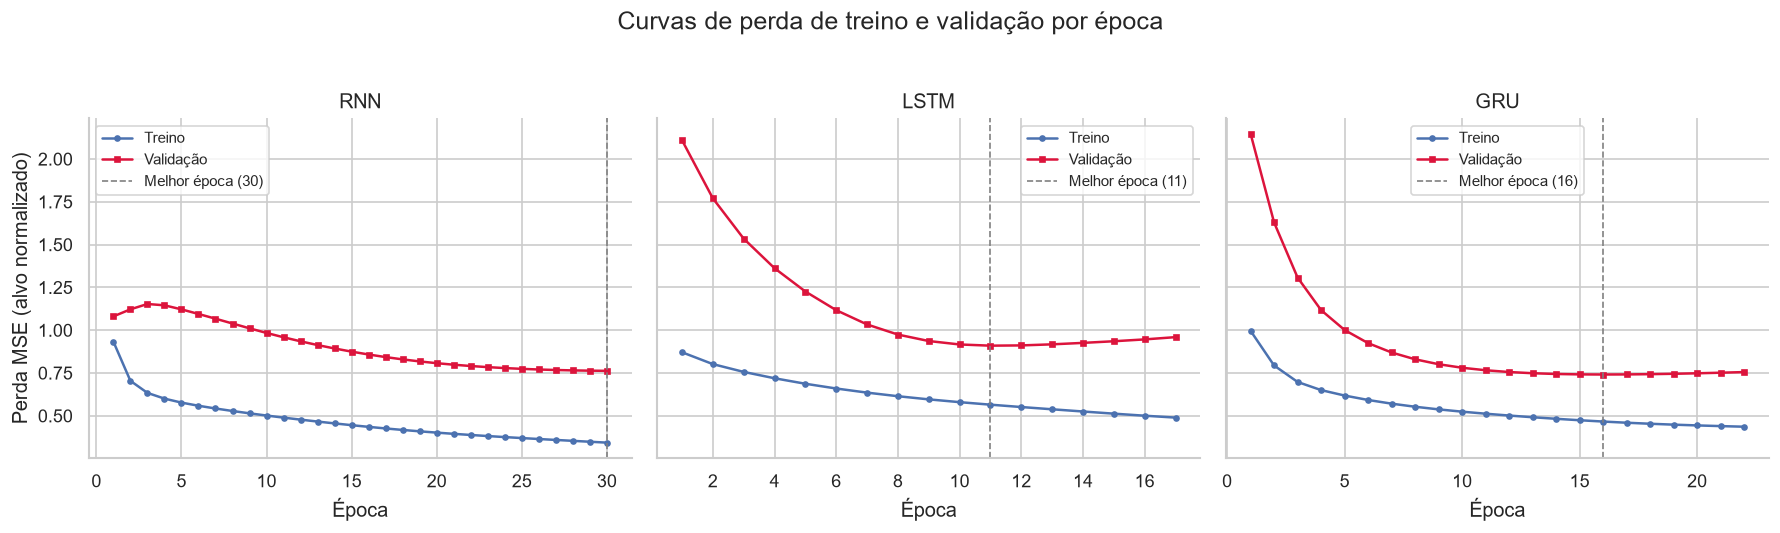

,rede,época,perda treino,perda validação,razão val/treino
0,RNN,1 (primeira),0.9328,1.0801,1.1578
1,RNN,30 (melhor),0.3427,0.7621,2.2237
2,RNN,30 (última),0.3427,0.7621,2.2237
3,LSTM,1 (primeira),0.8707,2.1095,2.4228
4,LSTM,11 (melhor),0.5644,0.9091,1.6106
5,LSTM,17 (última),0.4890,0.9589,1.9610
6,GRU,1 (primeira),0.9958,2.1472,2.1561
7,GRU,16 (melhor),0.4659,0.7406,1.5897
8,GRU,22 (última),0.4357,0.7548,1.7324


In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, nome in zip(eixos, redes):
    h = curvas_treino[nome]
    epocas = np.arange(1, len(h['loss']) + 1)
    melhor = int(np.argmin(h['val_loss'])) + 1
    ax.plot(epocas, h['loss'], marker='o', ms=3, label='Treino')
    ax.plot(epocas, h['val_loss'], marker='s', ms=3, color='crimson', label='Validação')
    ax.axvline(melhor, color='gray', ls='--', lw=1, label=f'Melhor época ({melhor})')
    ax.set_title(nome)
    ax.set_xlabel('Época')
    ax.legend(fontsize=9)
eixos[0].set_ylabel('Perda MSE (alvo normalizado)')
fig.suptitle('Curvas de perda de treino e validação por época', y=1.03, fontsize=15)
fig.tight_layout()
plt.show()

# Valores que sustentam a análise: 1ª época, melhor época e última época de cada rede.
linhas = []
for nome in redes:
    h = curvas_treino[nome]
    melhor = int(np.argmin(h['val_loss']))
    for rotulo, i in (('primeira', 0), ('melhor', melhor), ('última', len(h['loss']) - 1)):
        linhas.append({'rede': nome, 'época': f'{i + 1} ({rotulo})',
                       'perda treino': h['loss'][i], 'perda validação': h['val_loss'][i],
                       'razão val/treino': h['val_loss'][i] / h['loss'][i]})
display(pd.DataFrame(linhas).round(4))


**(c)** Resumo das curvas (MSE do alvo padronizado; valores da tabela acima):

| Rede | Validação na época 1 | Menor validação (época) | Validação na última época | Treino da melhor à última |
|:---|---:|---:|---:|---:|
| RNN | 1,08 | 0,76 (30) | 0,76 (30) | 0,34 |
| LSTM | 2,11 | 0,91 (11) | 0,96 (17) | 0,56 → 0,49 |
| GRU | 2,15 | 0,74 (16) | 0,75 (22) | 0,47 → 0,44 |

**RNN.** A validação sobe um pouco nas três primeiras épocas e depois cai sem parar até a época 30, que é o teto. A parada antecipada nunca foi acionada. Lemos isso como treino interrompido pelo limite de épocas, isto é, a rede provavelmente ainda tinha o que aprender (subajuste por falta de iterações). Um contraponto: a validação passou de 1,16 vezes para 2,22 vezes a perda de treino, então o treino já avançava mais depressa que a validação.

**LSTM.** Depois da época 11 a validação piora (0,91 → 0,96) enquanto o treino segue melhorando (0,56 → 0,49). É o desenho típico de sobreajuste, e a parada antecipada devolveu os pesos da época 11. Mesmo no melhor ponto, 0,91 fica perto de 1,0, que é o erro de prever sempre a média do treino.

**GRU.** Chega a 0,74 na época 16 e fica praticamente parada até a 22 (0,75), com o treino caindo pouco. Sobreajuste leve, contido pela parada.

As três curvas de treino são suaves e nenhuma divergiu; a validação oscila mais porque tem só 57 dias. Em todas, a validação fica acima do treino desde o início, e isso não é só sobreajuste: a validação cai em dezembro–fevereiro, com NO₂ mais alto e mais variável que o período de treino.

**Grau de certeza.** São leituras de uma execução por rede, com uma semente. Servem como suspeita, não como prova; para confirmar seria preciso repetir com várias sementes e ver se o padrão se mantém.

**O que faríamos.** Na LSTM e na GRU, diminuir a rede (8 unidades) ou incluir `dropout`/`recurrent_dropout`. Na RNN, o problema aparente é o contrário, então a medida seria dar mais épocas ou uma taxa de aprendizado um pouco maior. Para todas, validar em mais de um bloco temporal (*walk-forward*) em vez de um único trecho de 57 dias.

In [7]:
def calcular_erros(y_real, y_prev):
    """MAE e RMSE na unidade original (µg/m³)."""
    return (mean_absolute_error(y_real, y_prev),
            float(np.sqrt(mean_squared_error(y_real, y_prev))))

registros = []
for nome, modelo in redes.items():
    h = curvas_treino[nome]
    mae, rmse = calcular_erros(y_val, estimativas_val[nome])
    registros.append({
        'modelo': nome,
        'parâmetros': modelo.count_params(),
        'épocas executadas': len(h['loss']),
        'melhor época (val_loss)': int(np.argmin(h['val_loss'])) + 1,
        'tempo de treino (s)': round(duracoes[nome], 1),
        'MAE validação (µg/m³)': round(mae, 2),
        'RMSE validação (µg/m³)': round(rmse, 2),
    })
comparativo_redes = pd.DataFrame(registros).set_index('modelo')
display(comparativo_redes)

# Seleção entre as redes: menor MAE de validação; empate -> menos parâmetros.
ranking_redes = comparativo_redes.sort_values(['MAE validação (µg/m³)', 'parâmetros'])
MELHOR_REDE_VAL = ranking_redes.index[0]
print(f'Rede com menor MAE de validação: {MELHOR_REDE_VAL} '
      f'({ranking_redes.iloc[0]["MAE validação (µg/m³)"]:.2f} µg/m³, '
      f'{int(ranking_redes.iloc[0]["parâmetros"])} parâmetros)')


,parâmetros,épocas executadas,melhor época (val_loss),tempo de treino (s),MAE validação (µg/m³),RMSE validação (µg/m³)
modelo,,,,,,
RNN,353,30,30,6.4,16.72,21.91
LSTM,1361,17,11,4.6,19.73,23.93
GRU,1073,22,16,7.3,16.74,21.60


Rede com menor MAE de validação: RNN (16.72 µg/m³, 353 parâmetros)


**(d)** Ficamos com a **RNN simples**: MAE de validação de **16,72 µg/m³**, o menor da tabela (GRU 16,74; LSTM 19,73).

A distância para a GRU é de 0,02 µg/m³, pequena demais para ser tratada como diferença real com 57 dias e uma semente; a GRU, inclusive, tem RMSE um pouco menor (21,60 contra 21,91). O que decide a favor da RNN é que ela vence no critério combinado (MAE) e ainda é a rede mais leve: 353 parâmetros contra 1.073, com tempo de treino equivalente. A LSTM, a maior das três, teve o pior resultado e sinais de sobreajuste. Um ponto de atenção sobre a RNN: sua melhor época foi a 30, o teto, então o valor obtido depende desse limite.

Isso é um resultado sobre esta configuração, nesta partição e com esta semente. Não concluímos que redes recorrentes simples sejam melhores que GRU ou LSTM; bastaria outra semente para a GRU passar à frente.

## 4. Baseline, teste e decisão

(a) Baseline de persistência e escolha do candidato, registrada antes do teste. (b) Métricas de teste das quatro abordagens e gráfico dos últimos 50 dias. (c) Discussão dos resultados.

In [8]:
# Baseline de persistência: previsão = NO2 do último dia da janela (t-1), já em µg/m³.
estimativas_val['Persistência'] = X_val_bruto[:, -1, COL_NO2]
mae_p, rmse_p = calcular_erros(y_val, estimativas_val['Persistência'])

# Acrescenta o baseline à comparação da seção 3 (sem retreinar nenhuma rede).
registro_baseline = pd.DataFrame([{
    'modelo': 'Persistência', 'parâmetros': 0, 'épocas executadas': 0,
    'melhor época (val_loss)': 0, 'tempo de treino (s)': 0.0,
    'MAE validação (µg/m³)': round(mae_p, 2), 'RMSE validação (µg/m³)': round(rmse_p, 2),
}]).set_index('modelo')
comparativo_val = pd.concat([registro_baseline, comparativo_redes])
comparativo_val['Δ MAE vs. persistência (%)'] = (
    100 * (comparativo_val['MAE validação (µg/m³)'] / round(mae_p, 2) - 1)).round(1)
display(comparativo_val)

# Critério registrado ANTES do teste: menor MAE de validação (comparado com 2 casas decimais,
# em µg/m³); em caso de empate, vence o candidato de menor complexidade (menos parâmetros;
# a persistência tem 0 parâmetros e não exige treinamento).
ranking_val = comparativo_val.sort_values(['MAE validação (µg/m³)', 'parâmetros'])
CANDIDATO_FINAL = ranking_val.index[0]
print('Ordenação pela validação:', ' < '.join(ranking_val.index))
print(f'CANDIDATO ESCOLHIDO (fixado antes de consultar o teste): {CANDIDATO_FINAL} '
      f'| MAE de validação = {ranking_val.iloc[0]["MAE validação (µg/m³)"]:.2f} µg/m³')


,parâmetros,épocas executadas,melhor época (val_loss),tempo de treino (s),MAE validação (µg/m³),RMSE validação (µg/m³),Δ MAE vs. persistência (%)
modelo,,,,,,,
Persistência,0,0,0,0.0,19.14,24.60,0.0
RNN,353,30,30,6.4,16.72,21.91,-12.6
LSTM,1361,17,11,4.6,19.73,23.93,3.1
GRU,1073,22,16,7.3,16.74,21.60,-12.5


Ordenação pela validação: RNN < GRU < Persistência < LSTM
CANDIDATO ESCOLHIDO (fixado antes de consultar o teste): RNN | MAE de validação = 16.72 µg/m³


**(a)** Persistência na validação: MAE **19,14** e RMSE **24,60 µg/m³**. Com ela na tabela, a classificação por MAE fica RNN (16,72), GRU (16,74), persistência (19,14) e LSTM (19,73).

**Decisão registrada antes do teste: RNN simples.** Regra usada: menor MAE de validação, comparado com duas casas decimais; se dois candidatos empatassem, ficaria o de menos parâmetros (a persistência conta como zero). Não foi preciso desempatar.

Frente à persistência, a RNN erra 12,6% menos e a GRU 12,5% menos; a LSTM erra 3,1% a mais, ou seja, perdeu para a regra de repetir o dia anterior. Daqui em diante nada é reajustado: a próxima célula apenas mede o teste.

,selecionado na validação,MAE validação (µg/m³),RMSE validação (µg/m³),MAE teste (µg/m³),RMSE teste (µg/m³),viés médio teste (µg/m³),Δ MAE teste vs. persistência (%)
modelo,,,,,,,
Persistência,,19.14,24.60,18.78,24.09,0.20,0.00
RNN,SIM,16.72,21.91,18.66,24.01,-8.24,-0.60
LSTM,,19.73,23.93,18.73,24.93,1.29,-0.30
GRU,,16.74,21.60,17.15,22.23,-5.09,-8.70



Selecionado pela validação: RNN
Ordenação na validação: RNN < GRU < Persistência < LSTM
Ordenação no teste    : GRU < RNN < LSTM < Persistência


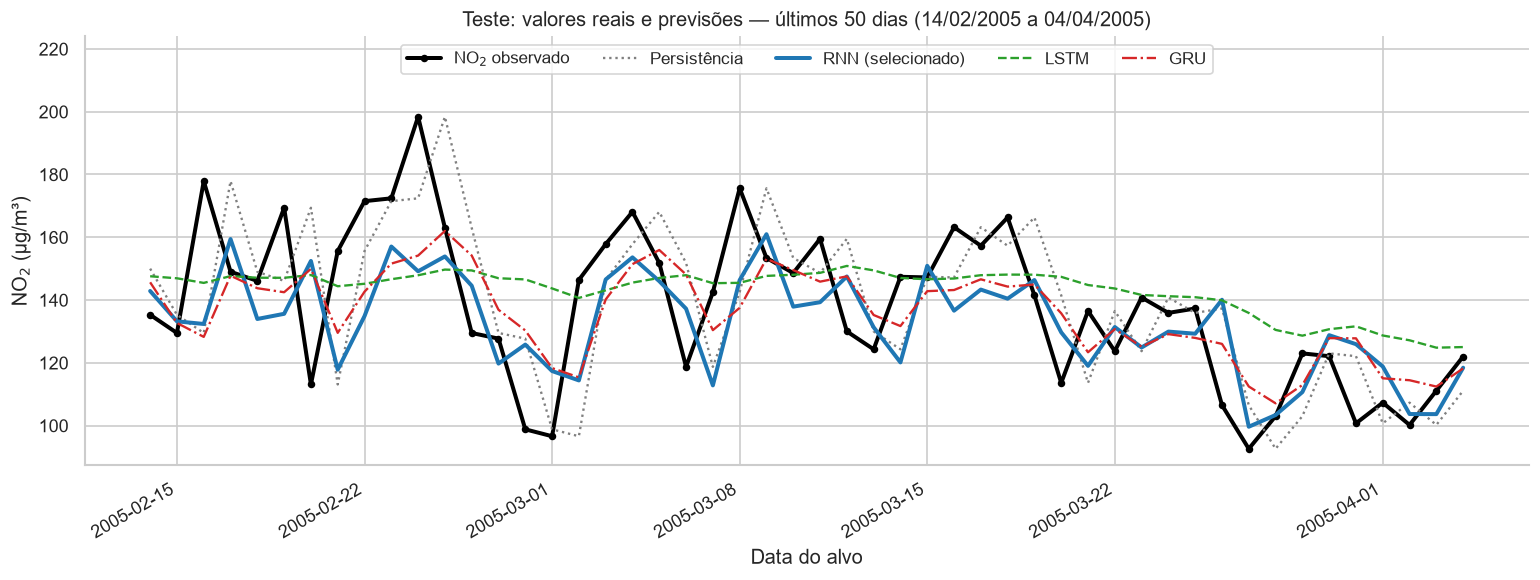

In [9]:
# Primeira e única consulta ao teste: redes, hiperparâmetros e escolha já estão fixados.
estimativas_teste = {'Persistência': X_teste_bruto[:, -1, COL_NO2]}
for nome, modelo in redes.items():
    estimativas_teste[nome] = para_ug_m3(modelo.predict(X_teste, verbose=0))   # volta para µg/m³

registros_teste = []
for nome in comparativo_val.index:
    mae_v, rmse_v = calcular_erros(y_val, estimativas_val[nome])
    mae_t, rmse_t = calcular_erros(y_teste, estimativas_teste[nome])
    registros_teste.append({
        'modelo': nome,
        'selecionado na validação': 'SIM' if nome == CANDIDATO_FINAL else '',
        'MAE validação (µg/m³)': round(mae_v, 2), 'RMSE validação (µg/m³)': round(rmse_v, 2),
        'MAE teste (µg/m³)': round(mae_t, 2), 'RMSE teste (µg/m³)': round(rmse_t, 2),
        'viés médio teste (µg/m³)': round(float(np.mean(estimativas_teste[nome] - y_teste)), 2),
    })
resultado_teste = pd.DataFrame(registros_teste).set_index('modelo')
resultado_teste['Δ MAE teste vs. persistência (%)'] = (
    100 * (resultado_teste['MAE teste (µg/m³)'] / resultado_teste.loc['Persistência', 'MAE teste (µg/m³)'] - 1)).round(1)

def realcar_escolhido(linha):
    """Realça a linha do candidato selecionado pela validação."""
    estilo = 'background-color: #fff3b0; font-weight: bold' if linha.name == CANDIDATO_FINAL else ''
    return [estilo] * len(linha)

display(resultado_teste.style.apply(realcar_escolhido, axis=1).format(precision=2))
print(f'\nSelecionado pela validação: {CANDIDATO_FINAL}')
print('Ordenação na validação:', ' < '.join(resultado_teste.sort_values('MAE validação (µg/m³)').index))
print('Ordenação no teste    :', ' < '.join(resultado_teste.sort_values('MAE teste (µg/m³)').index))

# Valores reais e previsões das quatro abordagens nos últimos 50 dias do teste.
n_final = min(50, len(y_teste))
d = dias_teste[-n_final:]
tracos = {'Persistência': dict(color='gray', ls=':', lw=1.4),
           'RNN': dict(color='#1f77b4', ls='-', lw=1.4),
           'LSTM': dict(color='#2ca02c', ls='--', lw=1.4),
           'GRU': dict(color='#d62728', ls='-.', lw=1.4)}

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(d, y_teste[-n_final:], color='black', lw=2.4, marker='o', ms=3.5, label='NO$_2$ observado')
for nome, estilo in tracos.items():
    extra = dict(estilo, lw=2.4) if nome == CANDIDATO_FINAL else estilo
    rotulo = f'{nome} (selecionado)' if nome == CANDIDATO_FINAL else nome
    ax.plot(d, estimativas_teste[nome][-n_final:], label=rotulo, **extra)
ax.set_title(f'Teste: valores reais e previsões — últimos {n_final} dias '
             f'({d.min():%d/%m/%Y} a {d.max():%d/%m/%Y})')
ax.set_xlabel('Data do alvo')
ax.set_ylabel('NO$_2$ (µg/m³)')
ax.set_ylim(top=ax.get_ylim()[1] * 1.10)          # espaço para a legenda acima das curvas
ax.legend(ncol=5, loc='upper center', fontsize=10)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()


**(c)**

**1. O teste confirmou a validação?** Parcialmente. A RNN escolhida seguiu à frente da persistência, mas por quase nada: 18,66 contra 18,78 µg/m³ (−0,6%), quando na validação a vantagem era de 12,6%. O MAE dela piorou cerca de 2 µg/m³ de um conjunto para o outro; o da GRU, só 0,4.

**2. A ordem mudou, e registramos isso como limitação.** Validação: RNN, GRU, persistência, LSTM. Teste: GRU (17,15), RNN (18,66), LSTM (18,73), persistência (18,78). Não trocamos de modelo: escolher a GRU agora seria usar o teste para selecionar, e o número deixaria de ser uma estimativa honesta. O resultado final do experimento é o da RNN. A lição é que 0,02 µg/m³ de diferença na validação não separava RNN de GRU.

**3. O que MAE e RMSE dizem juntos.** O MAE dá o erro de um dia comum, entre 17 e 19 µg/m³. O RMSE fica 5 a 6 µg/m³ acima em todas as abordagens, sinal de alguns dias com erro bem maior; no gráfico eles coincidem com subidas e quedas bruscas, que as previsões só acompanham com atraso. A LSTM mostra por que olhar as duas: tem MAE parecido com o da persistência (18,73) e o pior RMSE (24,93). Vimos também o sinal do erro: a RNN prevê em média 8,2 µg/m³ abaixo do observado no teste (GRU, 5,1 abaixo), enquanto a persistência quase não tem viés (+0,2).

**4. Vale a complexidade?** Com este resultado, não. Treinar, normalizar e manter uma rede para ganhar 0,12 µg/m³ sobre uma regra sem parâmetros, e ainda com tendência a subestimar, não se justifica.

**5. O que significa a persistência ser tão competitiva.** O NO₂ de um dia se parece muito com o do dia anterior, e é daí que vem quase toda a previsibilidade a um dia. As duas semanas de histórico dos quatro poluentes acrescentaram pouco; o que explicaria as viradas bruscas (vento, chuva, temperatura, dia da semana) não está na base. É um resultado legítimo: mostra que a rede precisa provar ganho antes de ser adotada.

**Limitações.** Teste único de 57 dias (fevereiro a abril de 2005), uma semente por rede, teto de 30 épocas, um ano de dados de uma só cidade e níveis de NO₂ diferentes entre treino, validação e teste.

## 5. Memória, horizonte e limites de aplicação

Três questões conceituais ligadas ao experimento: (a) se LSTM ou GRU sempre superam uma RNN simples; (b) se o erro medido vale para prever sete dias de uma só vez; (c) o que falta para usar o modelo como informação ao cidadão em uma cidade brasileira.

**(a)** Discordamos do "sempre". Toda rede recorrente carrega um estado que resume o que já leu da sequência. Na RNN simples esse estado é recalculado por inteiro a cada passo, e por isso a influência dos primeiros passos (e o gradiente associado) vai se perdendo em sequências longas. As portas da LSTM e da GRU são pesos aprendidos que regulam quanto do estado antigo é preservado e quanto é substituído, o que ajuda a aprender relações entre pontos distantes. Só que essa ajuda depende de existir dependência longa para aprender e de haver dados para ajustar os parâmetros a mais. Aqui a sequência tem 14 passos, o dia anterior já explica boa parte do alvo e o treino tem 263 amostras. No nosso experimento, a LSTM (1.361 parâmetros) foi a pior na validação (19,73), abaixo até da persistência, enquanto a RNN (353 parâmetros) teve 16,72, empatada com a GRU (16,74). No teste a GRU ficou à frente (17,15) e RNN e LSTM se igualaram (18,66 e 18,73). O que isso mostra é que portas não asseguram erro menor nesta base; não mostra que a RNN seja superior, pois houve uma configuração e uma semente por família.

**(b)** Não pode. O valor que medimos (18,66 µg/m³ para a RNN) é o erro de prever **amanhã** conhecendo os 14 dias reais até hoje, com a janela renovada a cada dia. Na tarefa de sete dias: o alvo fica mais distante, e a semelhança com o último dia observado, que sustenta a previsão, diminui a cada dia; para prever do segundo dia em diante faltariam as medições dos quatro poluentes dos dias intermediários, e a rede só devolve NO₂; e, se preenchêssemos a janela com as próprias previsões, cada erro entraria na previsão seguinte e a rede receberia entradas que nunca viu no treino. O erro de sete dias tende a ser maior, e o nosso número o subestimaria. O experimento teria de ser refeito com outro alvo: para cada origem $t$, entrada com os 14 dias observados até $t$ e saída com os sete valores $NO_{2,t+1},\dots,NO_{2,t+7}$, nova divisão cronológica com essa regra e erro informado separadamente para cada um dos sete horizontes, ao lado da persistência medida do mesmo jeito.

**(c)** Três motivos. O MAE global mistura todos os dias, e os dias de NO₂ alto, que são minoria e os que mais interessam ao cidadão, pesam pouco nele. O MAE ignora a direção do erro: prever **abaixo** do real passa a ideia de ar melhor do que está e pode levar alguém a dispensar um cuidado; prever **acima** produz avisos sem motivo e, com a repetição, faz o público deixar de dar atenção ao serviço. No nosso teste a RNN errou para baixo em média (−8,2 µg/m³). E o modelo aprendeu com um ano de medições de uma cidade italiana em 2004–2005; frota, clima, relevo e equipamentos de uma cidade brasileira hoje são outros.

Antes de qualquer uso local, verificaríamos: (1) o desempenho com dados recentes das estações da própria cidade, em divisão temporal que cubra o ano todo e sempre comparado à persistência; (2) o erro separado por nível de concentração e por direção, contando quantos dias altos o modelo deixou de apontar e quantos avisos seriam falsos, com as faixas adotadas pelo órgão ambiental responsável. Ainda assim, a previsão seria só um apoio aos boletins oficiais e não uma orientação de saúde.

## Referências

VITO, Saverio. *Air Quality* [conjunto de dados]. UCI Machine Learning Repository, 2008. DOI: https://doi.org/10.24432/C59K5F.

MATHEWCHALO7. *AirQualityAnalysis* [repositório]. GitHub. Arquivo de médias diárias `daily_avg_pollutants.csv`. Disponível em: https://github.com/mathewchalo7/AirQualityAnalysis.

KERAS. *Recurrent layers* e *EarlyStopping*. Documentação do Keras 3. Disponível em: https://keras.io/api/.